# 11-屏幕显示与触摸驱动

> 先让像素显示在正确的位置，再让手指坐标落到同一位置：总线、颜色、窗口、缓冲与事件都要有清楚的边界。

这是「嵌入式单片机一套通关」十二篇笔记的第 11 篇。承接第 08 篇的 I²C/SPI、第 06 篇 DMA 和第 10 篇存储器，本篇把 **OLED → ST7789 彩屏 → 局部刷新/DMA → CST816T 触摸 → 坐标变换与交互** 串成一条学习路线。

完成本篇，应能独立解释：背光亮为什么仍可能没有图像？RGB565 的位布局和线上字节顺序有什么区别？240×280 的坐标如何映射到控制器？DMA 发完后何时可复用缓冲？触摸中断、按下/抬起和坐标旋转如何协作？

本篇为中文 Markdown 笔记，含自绘示意图、接口约定、算法和验收清单。**未进行 SDK 编译、烧录、上板运行或电气测量**；`board_*`、`app_*`、`lcd_*`、`touch_*` 示例接口均需要自行适配，不是 GD32 库自带 API。


## 1. 本篇范围、平台与来源

| 课程页面 | 本篇内容 |
|---|---|
| I2C OLED | 总线与器件分层、软件/硬件 I²C、二维缓冲 |
| SPI OLED | SPI 移植、片选、命令/数据、字库资源 |
| 1.69寸手表屏-显示 | 240×280、ST7789、SPI0、GPIO、偏移与驱动移植 |
| 1.69寸手表屏-触摸 | CST816T、I²C、EXTI4、坐标寄存器 |
| RGB565 RGB888 | 色深、位数、颜色表示 |
| LVGL兼容手表屏 | 后续显示/输入接口衔接，具体 UI 留第12篇 |

本篇阅读了上述 **6 个页面的可访问正文和已显示的代码片段**，视觉核对了 OLED 接线、手表屏连接器及课程分辨率配置图。课程长代码编辑器和附件工程未全部展开或下载。另阅读课程引用的 ST7789 参考库 README 和固定提交的 `st7789.h/.c`、配置模板，作为移植对照，不声称它已经适配课程的 240×280 板。

系列示例沿用 **GD32F407VET6、匹配 GD32F4xx SPL/CMSIS、C99**。OLED 页中还出现 GD32F470、STM32F407 例程，不能通过换头文件就宣称所有芯片完全一致。复用编号、IRQ、DMA、时钟、可用 RAM 区域均按实际型号核对。

阅读路线：第2～5节分清模块和移植边界；第6～16节完成彩屏数据路径；第17～22节理解OLED、带宽和DMA；第23～28节设计触摸输入；第29～32节整合、排错、自测。SSD1306 的128×64页结构属于**明确标出的常见教学模型**，课程OLED具体控制器未在本篇完整核实。


## 2. 显示和触摸是两套设备

“触摸屏”通常是显示面板、触摸感应层和控制芯片组成的模块。课程手表屏显示采用 ST7789（图片标 ST7789V），触摸采用 CST816T；显示走 SPI，触摸走 I²C，并额外有中断和复位脚。

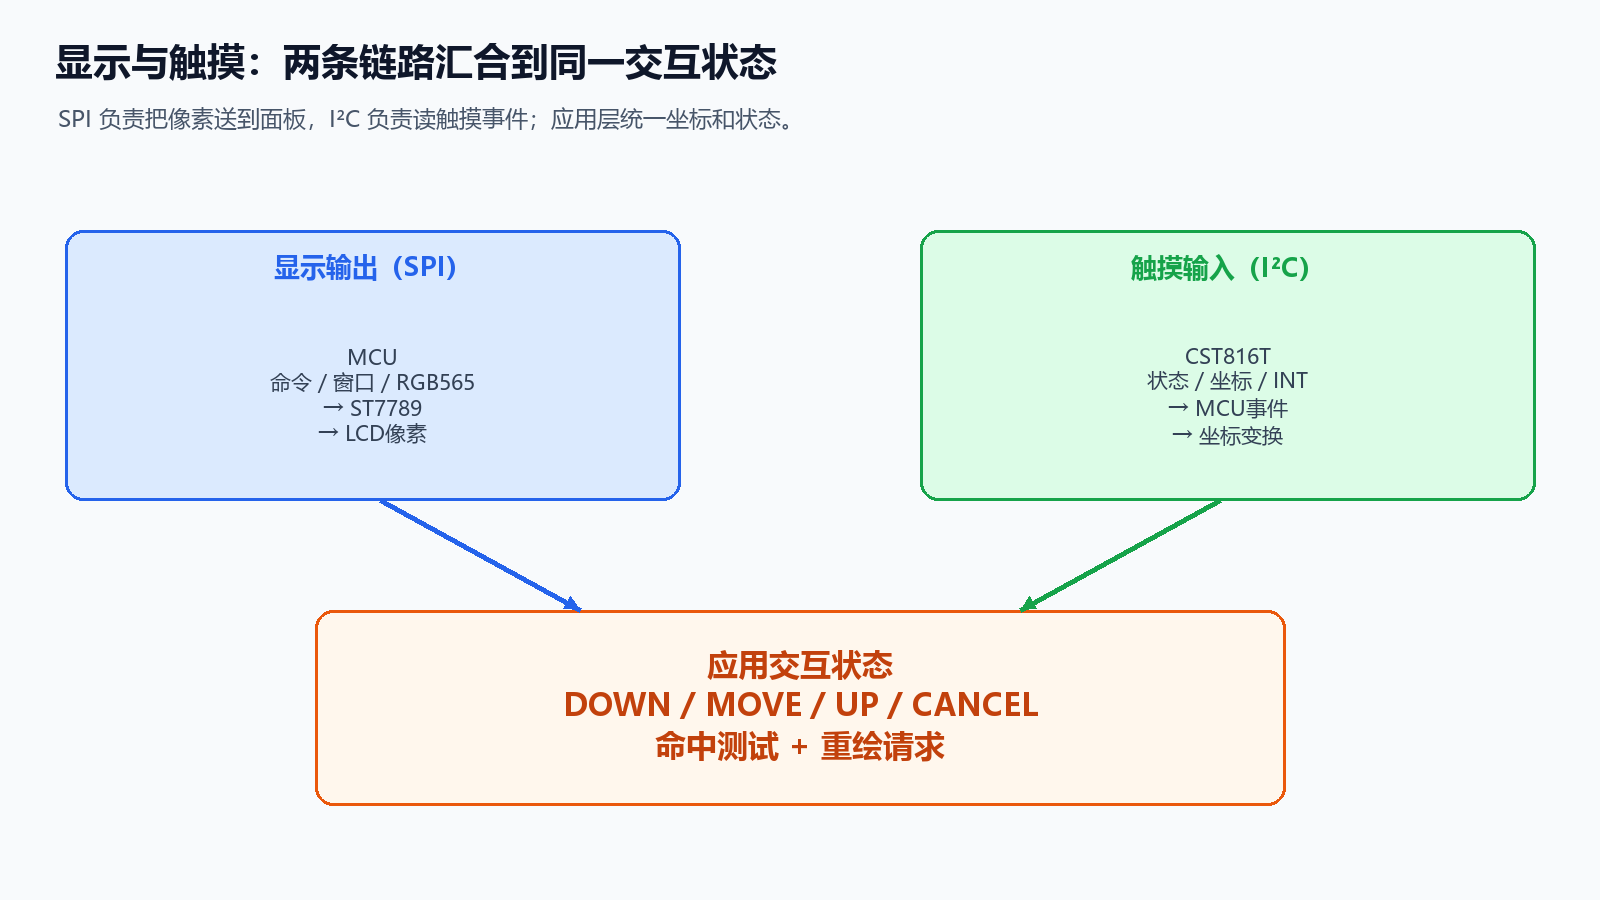

| 链路 | MCU 发出/接收 | 成功的含义 |
|---|---|---|
| 显示 | 命令、窗口、颜色字节 | 目标窗口收到正确像素 |
| 触摸 | 寄存器状态、坐标 | 一帧输入有效且坐标映射正确 |
| 交互 | 命中测试、状态、重绘 | 按下、移动、抬起与画面一致 |

显示正常不证明触摸 I²C 可用；触摸坐标能打印不证明显示方向匹配。调试时先分别完成裸显示和彩屏四角测试，再打印触摸四角，最后叠加标记。不要一上来把所有问题都归到图形库。

触摸控制器通常先检测手指，再通过 INT 通知 MCU 读取事件。课程文字“外部中断通知芯片干活”容易误解：EXTI 是 MCU 的输入响应，触摸测量由触摸控制器完成，MCU读取结果；特殊扫描/唤醒行为按触摸固件手册判断。


## 3. LCD、OLED、控制器与显存

LCD 依靠背光和液晶调制显示，OLED 像素本身发光。ST7789 模块中，MCU 通常把像素写入控制器的显示 RAM，由控制器持续扫描面板；MCU不需要不停重发同一静止图像才能“保持亮”。

区分三处存储：

| 存储位置 | 存什么 | 更新方式 |
|---|---|---|
| MCU RAM | 绘图缓冲、队列、DMA块 | CPU/DMA，断电丢失 |
| 控制器 RAM | 已写入的屏幕像素 | 通过命令/数据总线更新 |
| MCU/外部 Flash、SD | 字体、图片资源 | 第10篇的存储与文件接口 |

不是所有屏幕都有同一种RAM组织。带RGB并行扫描接口的裸面板、电子纸、SPI彩屏、单色OLED的刷新方式不同。不能把“ST7789窗口写入”直接套到任何显示设备。

背光由BLK/BL控制，图像由显示命令和像素RAM决定。背光亮只能说明发光路径工作；初始化、退出睡眠、显示使能、DC和窗口设置错误都可能导致黑屏。OLED没有LCD背光，不要给SSD1306教学模型增加“开背光”的步骤。


## 4. 手表屏接线与共享总线

课程连接器图已核对：

| 功能 | 课程 MCU 引脚 | 用途 |
|---|---|---|
| LCD SCL/CLK | PA5 | SPI0_CLK |
| LCD SDA/DIN | PA7 | SPI0_MOSI |
| LCD CS | PB0 | GPIO片选，低有效 |
| LCD DC | PB1 | 命令/数据选择 |
| LCD RST | PD6 | 显示复位 |
| LCD BLK | PB10 | 背光控制 |
| TP SCL | PB6 | 触摸I²C时钟 |
| TP SDA | PB7 | 触摸I²C数据 |
| TP INT | PB4 | EXTI4事件通知 |
| TP RST | PD7 | 触摸复位 |

彩屏上的“SDA/SCL”标号在此处对应 **SPI 数据/时钟**，不等于它使用 I²C。是否需要MISO取决于读取需求和模块是否引出读线；课程图未给彩屏MISO路径，不能用未连接的读ID“检测到”屏幕。显示复位PD6和触摸复位PD7也不能混用。

第10篇Flash同样使用PA5/PA7，Flash片选为PA4，LCD片选为PB0。共享时保持其它CS无效，在持有总线锁时设置该设备的mode、速率、位宽并执行完整事务。PB6/7还可挂OLED等I²C器件，需地址不冲突、总线锁和上拉设计正确。

背光控制脚可能接模块使能或晶体管，不一定直接驱动LED。课程表格不能证明任意模块允许GPIO承担背光电流；电压、驱动电路、有效电平和PWM方式按实物原理图。插接端子也要核对朝向、针序和供电，不能只凭线色。

配置归属也要分清：板层设置GPIO电平/复用，LCD层控制自己CS/DC，触摸层设置EXTI路由和自己的RST，总线层提供串行访问和超时。将OLED或触摸的PB6/PB7初始化重复写在多个设备init里，可能覆盖原来配置；推荐先统一初始化bus，再probe/init各器件。

插接式模块的端子“无需手动接线”只是机械便利，不能免去检查板的供电、接口类型和针序；本篇引用的是已看到的课程连接器图，不代表所有同尺寸屏幕。


## 5. 移植分层：换平台接口，保留协议

建议把移植分成三层：

```text
应用图形：填充/文字/波形/标记
    ↓
控制器驱动：初始化、窗口、像素格式、显示状态
    ↓
board接口：GPIO、SPI/I²C、延时、锁、DMA、超时
```

课程参考驱动原用STM32 HAL，迁到GD32需要适配头文件、GPIO、SPI、延时和错误返回。单纯把 `HAL_SPI_Transmit` 名字换成另一个函数，不保证发送长度、等待结束、CS、DC和超时语义相同。

工程组织可用 Hardware/ST7789、Hardware/CST816T、Library/bus、App/display。Keil分组中加入.c，include path加入头目录，并启用所需SPL源文件。避免一边保留旧初始化，一边又在新board层初始化同一SPI，导致后者覆盖前者配置。

宏应有检查：分辨率只选一个、方向属于0～3、缓冲至少能放一个像素、颜色深度与协议一致。数值开关 `#define TOUCH_XY_PRINT 0` 应用 `#if TOUCH_XY_PRINT`；`#ifdef` 只检查是否定义，值为0也会进入打印分支。

C99示例用十六进制位掩码。课程触摸片段的 `0b...` 在严格C99不是标准写法，编译器可能以扩展接受；学习笔记改用 `0x0F`、`0x0FFF`，避免把编译器扩展当成标准语法。


## 6. RGB888、RGB565与“8位颜色”

RGB888是每通道8位，共24位/像素：R、G、B各0～255，若紧密打包通常3B。RGB565共16位/像素，R5、**G6**、B5；绿色范围0～63，红蓝0～31。

| 格式 | R/G/B位数 | 常见紧密字节数 | 可表示组合数 |
|---|---|---:|---:|
| 单色 | 1bit亮/灭 | 1/8 B/像素 | 2 |
| RGB565 | 5/6/5 | 2 B/像素 | 65,536 |
| RGB888 | 8/8/8 | 3 B/像素 | 16,777,216 |
| 带alpha的32位格式 | 常见8/8/8/8 | 4 B/像素 | 含透明度信息 |

“8位/通道”与“8位/像素”不同。RGB888不是总共8位的索引色；PNG/JPEG也有多种编码、色彩和压缩结构，不是把文件原始字节直接当RGB数组就能显示。

课程RGB565页面把绿、蓝位数写反，本篇以标准 **R[15:11]、G[10:5]、B[4:0]** 为准。`#3469AA` 表示R=52、G=105、B=170；颜色数值、内存布局、屏幕RGB/BGR模式要分别检查。


## 7. RGB888转换为RGB565

使用高位截断的一种独立算法：

```c
uint16_t app_rgb565(uint8_t r, uint8_t g, uint8_t b)
{
    return (uint16_t)(((uint16_t)(r >> 3) << 11) |
                      ((uint16_t)(g >> 2) << 5) |
                      (uint16_t)(b >> 3));
}
```

| 颜色 | RGB565 | 本篇线上字节示例 |
|---|---:|---|
| 黑 | 0x0000 | 00 00 |
| 白 | 0xFFFF | FF FF |
| 红 | 0xF800 | F8 00 |
| 绿 | 0x07E0 | 07 E0 |
| 蓝 | 0x001F | 00 1F |
| 黄 | 0xFFE0 | FF E0 |
| 青 | 0x07FF | 07 FF |

`#3469AA` 截断结果为 `0x3355`。这是截断规则；若用四舍五入，应明确公式并统一资源生成工具。不能混用两种规则后期待逐像素完全一样。

恢复到8位通道可按比例扩展 `r8≈r5×255/31`、`g8≈g6×255/63`，或位复制扩展。丢掉的低位无法恢复，梯度可能出现色带；抖动需权衡效果和计算成本。本篇不把色深增加当成所有噪声/颜色故障的解决方案。

不要用 `memset(buf, color, sizeof buf)` 填RGB565数组；memset重复的是一个字节，不是16位颜色。红色缓冲应逐像素赋值或预先生成F8 00重复字节流。


## 8. 字节顺序与RGB/BGR是两种问题

在常见小端MCU内存中，`uint16_t c=0xF800` 的字节是00 F8；ST7789本篇采用的16bit数据流需要F8 00。把uint16_t数组直接转换BYTE*并用8bit SPI发送，可能传反颜色。

显式编码最容易核对：

```c
void app_rgb565_be(uint16_t color, uint8_t out[2])
{
    out[0] = (uint8_t)(color >> 8);
    out[1] = (uint8_t)color;
}
```

`MADCTL`中的RGB/BGR选择改变红蓝通道解释；交换字节改变16位数据的位位置，二者不能互相代替。症状可用纯红/绿/蓝三色定位：红蓝互换且绿正常优先看RGB/BGR；多种颜色都怪异优先看字节序、COLMOD、像素长度与传输位宽。

SPI“MSB first”只是单帧比特发送顺序；8bit帧下不能自动把小端数组中的两个字节调换。16bit SPI+DMA又有内存/外设数据宽度配置，必须看实际装载方式；不要同时在资源工具、驱动和图形库都swap一次又一次。

参考库的Fill_Color与DrawImage在不同路径处理字节方式不同，不能仅凭“函数名能用”认为所有图像输入都接受主机端序。本篇把线上格式作为接口合同，统一显式编码后再谈DMA优化。


## 9. 坐标、矩形与安全裁剪

竖屏240×280时，合法像素为 `0≤x<240`、`0≤y<280`，右下角为(239,279)。宽高是数量，不是最后索引。应用矩形推荐半开区间 `[x0,x1)×[y0,y1)`，面积为 `(x1-x0)(y1-y0)`。

一个使用有符号坐标、只裁剪目标矩形的C99算法：

```c
typedef struct { int32_t x0, y0, x1, y1; } app_rect_t;

bool app_clip_rect(app_rect_t *r, int32_t width, int32_t height)
{
    if (r == NULL || width <= 0 || height <= 0) return false;
    if (r->x0 >= r->x1 || r->y0 >= r->y1) return false;
    if (r->x0 < 0) r->x0 = 0;
    if (r->y0 < 0) r->y0 = 0;
    if (r->x1 > width) r->x1 = width;
    if (r->y1 > height) r->y1 = height;
    return r->x0 < r->x1 && r->y0 < r->y1;
}
```

输入反向矩形不默默交换端点，返回失败；完全在屏外返回失败，边缘部分裁剪。若入口是(x,y,w,h)，先验证w/h并在更宽类型中算终点，避免加法溢出。负坐标不要先转uint16_t后再判断，负值会变成很大的正数。

裁剪纯色填充只改变目标范围；裁剪图片还要改变源偏移和行跨度。本篇第16节说明stride，不能只缩小目标宽度却把源图片从第一个像素连续发送。

几个裁剪例子（逻辑屏240×280）：

| 输入半开矩形 | 裁剪结果 | 像素数量 |
|---|---|---:|
| [-5,5)×[-3,7) | [0,5)×[0,7) | 35 |
| [239,241)×[279,281) | [239,240)×[279,280) | 1 |
| [240,245)×[0,10) | 空 | 0 |
| [10,10)×[0,10) | 空 | 0 |
| [10,5)×[0,10) | 反向输入，拒绝 | 0 |

半开表示避免“w/h到底是否含最后点”的歧义。若画5px宽的线，从x10开始到x15不含；转换到控制器末点为14。与触摸命中用同样边界，两个相邻按钮共用边界时不会同时命中。


## 10. ST7789地址窗口与连续像素流

参考源码使用：

| 命令 | opcode | 含义 |
|---|---:|---|
| CASET | 0x2A | 列起止地址 |
| RASET | 0x2B | 行起止地址 |
| RAMWR | 0x2C | 开始写显示RAM |
| MADCTL | 0x36 | 地址方向、轴交换、RGB/BGR |
| COLMOD | 0x3A | 像素接口格式；参考库RGB565使用0x55 |
| SLPOUT / DISPON | 0x11 / 0x29 | 退出睡眠 / 开启显示 |

命令来自已读参考实现，初始化的全部电气/延时限制仍按实际ST7789后缀和面板手册核对。本篇不把初始化序列视为所有同芯片面板的通用保证。

应用半开窗口(10,20)～(30,35)含20×15=300像素；发送给控制器的是**包含末点**：x10～29、y20～34，总600B。若屏幕偏移(xoff,yoff)，传入控制器坐标加偏移后按高字节、低字节编码。

```text
DC=0: 2A → DC=1: Xstart_hi Xstart_lo Xend_hi Xend_lo
DC=0: 2B → DC=1: Ystart_hi Ystart_lo Yend_hi Yend_lo
DC=0: 2C → DC=1: 连续 N 个RGB565像素（2N字节）
```

默认行进顺序也与MADCTL有关，本篇以驱动合同中的行优先顺序为准。精确发够窗口的像素数，不靠“多写一点”填满；少写保留旧内容，多写可能回卷或写错区域。事务中不允许另一个任务插入窗口命令。

窗口字节可用一个独立编码算法。这里只编码已验证的逻辑半开范围，不执行硬件传输，offset用于教学条件模型：

```c
bool app_encode_window(app_rect_t r, uint16_t xoff, uint16_t yoff,
                       uint8_t col[4], uint8_t row[4])
{
    if (col == NULL || row == NULL ||
        r.x0 < 0 || r.y0 < 0 || r.x0 >= r.x1 || r.y0 >= r.y1)
        return false;
    uint32_t xs = (uint32_t)r.x0 + xoff;
    uint32_t xe = (uint32_t)(r.x1 - 1) + xoff;
    uint32_t ys = (uint32_t)r.y0 + yoff;
    uint32_t ye = (uint32_t)(r.y1 - 1) + yoff;
    if (xe > 65535u || ye > 65535u) return false;
    col[0] = (uint8_t)(xs >> 8); col[1] = (uint8_t)xs;
    col[2] = (uint8_t)(xe >> 8); col[3] = (uint8_t)xe;
    row[0] = (uint8_t)(ys >> 8); row[1] = (uint8_t)ys;
    row[2] = (uint8_t)(ye >> 8); row[3] = (uint8_t)ye;
    return true;
}
```

调用者另检查逻辑尺寸、有效控制器地址范围及方向。本函数只限制16bit编码，不证明所有65536地址都被实际控制器支持。全屏(0,0)～(240,280)、假设yoff20，对应列00 00 00 EF、行00 14 01 2B（y20～299）。

窗口命令、参数和像素流需要保持一致的驱动状态。低层若在每个helper内自行拉高CS，应确认控制器允许对应分段且无别的任务穿插；迁移时避免嵌套Select/UnSelect让外层以为CS持续有效。本篇将完整窗口操作交给同一总线锁和事务管理。


## 11. 240×280、方向与控制器偏移

屏幕可视尺寸不一定等于控制器地址RAM大小。例如在一个240×320地址模型里，240×280可视区域若居中，竖向偏移可能为20；**这只是条件示例，不是所有240×280屏固定为20**。面板安装、扫描方向和驱动逻辑都会影响偏移。

课程截图的240×280配置仍包含从240×240复制的80等不同方向值，并将WIDTH/HEIGHT固定为240/280。不能把“复制后改宏”当作四个方向都验收通过。横屏通常逻辑尺寸变为280×240，要同时修改窗口、绘图裁剪、资源和触摸映射。

方向配置用一张表管理：逻辑width/height、MADCTL、x/y offset、触摸映射。MADCTL的MX/MY/MV用于镜像与轴交换，但本篇的数学旋转编号不等于任意参考库的 `ST7789_ROTATION=0..3` 编号；要用四角测试建立对应关系。

验收图包含：左上标0、右上标1、右下标2、左下标3；1px四边框；中心十字；X向色条。整屏“红色能亮”看不出镜像、交换轴或20px偏移，四角与边框能快速区分。

控制器offset只在显示驱动加一次；触摸返回通常是面板坐标，不应机械加同一个RAM偏移，否则按钮命中会偏移。坐标原点、旋转和偏移分开记录。


## 12. 初始化：供电、复位、睡眠和背光

推荐分阶段检查，而非直接复制一长串magic numbers：

1. 稳定供电，所有CS无效，DC/RST/BLK处于板定义的安全状态。
2. 初始化GPIO和SPI，确认时钟/数据波形。
3. 按面板要求硬件复位，满足低脉宽和复位后等待。
4. 配置像素格式、方向和面板专用电源/扫描/gamma参数。
5. 退出睡眠并等待规定时间，开启显示。
6. 写黑底和三原色，再开启或调整背光验证图像。

顺序中的具体参数应沿用已验证卖家/板例并对照数据手册。参考库的硬复位、SLPOUT及电压/gamma序列仅代表该实现；本篇没有声称它在课程屏上已运行。

显示开启不等于背光开启，显示反相 `INVON/INVOFF` 也不等于RGB/BGR。部分面板需要不同反相配置，测试黑白和渐变并按面板资料判断，不把“色不对”全归到字节swap。

初始化失败要有返回状态：电气/总线超时、参数错误、屏幕未就绪各自记录。若模块没有读通道，可以通过逻辑分析和测试图验证写链路，不能假造返回ID当作硬件存在证据。


## 13. SPI发送接口：完成点决定CS/DC和缓冲

先实现同步的清晰合同：

```c
/* 需要board层实现，以下是合同，非现成库API */
bool board_spi_write_sync(const uint8_t *data, size_t bytes,
                          uint32_t timeout_ms);
void board_lcd_cs(bool selected);  /* selected=true -> CS低 */
void board_lcd_dc(bool data_mode);
```

成功返回意味着所有字节已从SPI移位器发完，函数不再借用data；失败意味着可能已发送前缀，不能默认一个字节都未发生。发送寄存器空只说明还能装数据，不等于最后一位发完；使用匹配SPL状态位检查实际结束。

片选由器件驱动管理，总线驱动不应在每字节任意拉高CS。选中后DC=0写命令，等待结束再DC=1写参数/像素，完整操作结束后释放CS和总线锁。DC在移位中途改变可能让最后一部分字节被解释错。

同步函数可分多段发送，受库长度类型/硬件计数限制；总长度用size_t管理，调用前检查。全屏134400B不能盲转成uint16_t长度；某库每次最多65535B并不代表所有GD32API同一限制，按所用接口分块。

超时之后要停DMA/传输、确认不再借用缓冲，再释放片选和锁。错误恢复需要明确屏幕窗口已不可信，下一次重新设完整窗口；不能返回false却让外设继续从函数栈读数据。


## 14. 批量填充矩形：一次设窗、多次写块

不要每个像素都发送完整窗口命令。纯色填充可以先裁剪，设置一次窗口，再把重复颜色字节按小块发送。本篇采用**同步发送**，短栈缓冲可安全在返回后复用：

```c
/* lcd_begin_window: 持总线锁、设半开窗口、发送RAMWR、进入data模式。
   成功后保持CS选中；失败时自行清理。
   lcd_end_window: 结束事务并释放锁；传输失败先终止外设。 */
bool app_fill_rect(app_rect_t r, uint16_t color)
{
    if (!app_clip_rect(&r, lcd_width(), lcd_height())) return true;
    size_t pixels = (size_t)(r.x1 - r.x0) * (size_t)(r.y1 - r.y0);
    uint8_t block[128];               /* 每块64个RGB565像素 */
    for (size_t i = 0; i < sizeof block; i += 2) {
        block[i] = (uint8_t)(color >> 8);
        block[i + 1] = (uint8_t)color;
    }
    if (!lcd_begin_window(r)) return false;
    bool ok = true;
    while (pixels != 0u) {
        size_t count = pixels < 64u ? pixels : 64u;
        if (!board_spi_write_sync(block, count * 2u, 100u)) {
            ok = false; break;
        }
        pixels -= count;
    }
    lcd_end_window(ok);
    return ok;
}
```

100ms仅为学习片段的调用参数，按块长度、速率和任务响应重算，不是面板规格。宽高限定为本篇小屏幕尺寸，若泛化到任意尺寸，乘法也做溢出检查。裁剪后为空在本示例视作“不需要画”的成功；真正参数错误是否另报由接口定义。

最后一块只写剩余像素，不必凑整128B；全屏240×280共67200像素，恰好1050块。以后迁到异步DMA，不能把栈数组block提交后立即返回，必须改为持久缓冲和完成通知。


## 15. 点、线、矩形、圆与文字

点接口先检查坐标，水平/垂直线可用窄矩形填充，矩形边框分四条线，圆/斜线可用整数算法。运算中保留有符号坐标处理负边缘，最终每个目标区域裁剪；不要让uint16_t的减法回卷变成巨大坐标。

绘图API的 `(x,y,w,h)` 和 `(x0,y0,x1,y1)` 不能混淆；后者还需约定末点包含与否。课程参考库有Fill、DrawRectangle等不同接口，本篇统一在app层用半开区间，再转控制器含末点。

只描边留下旧背景，填充覆盖整个区域。数字从“100”变“9”时若只画新字符，后面“00”仍可能保留；固定字段区域先填背景或画带背景字形，不用每次清全屏来解决。

字形是像素掩码，不是ASCII字节直接送屏幕。字体渲染需要字符编码→字形索引→点阵→前景/背景像素。把UTF-8中文每个字节都当一个ASCII索引会越界；第12篇再讨论图形库字体和控件。

先做最小诊断图，再图形组合：三原色、边框、对角线、棋盘格、固定ASCII。复杂圆和渐变出现问题时，先确认点与窗口正确，避免边学算法边改总线。

纯色小方块用fill_rect，不必用25次DrawPixel。字符前景/背景可先在条带生成像素再批量发送；每像素设窗口会耗费大量命令。字体表索引先检查支持的字符范围，再从只读字形表取数据，尤其避免signed char为负索引。

反相显示、亮度和视觉颜色也有区别。调高BLK仅改变LCD背光；改变gamma/反相是面板控制，不应当作“用户主题颜色”的替代。主题和控件色彩在像素/GUI层管理。


## 16. 图片、字库、stride与外部资源

240×280 RGB565全屏为134400B；RGB888紧密为201600B。一个.c文件大小1.3MB并不等于编译后恰好占1.3MB Flash，源码十六进制文字会放大，最终看map/链接统计。字体声明const并选必要字符，避免全部搬进RAM。

图片协议应说明宽、高、像素格式、线上字节序、行跨度stride和压缩方式。连续RGB565的stride通常为width×2，但BMP等格式可能带行对齐和倒序，PNG/JPEG还需要解码，不能直接f_read后当像素发送。

例：源图100×50、每行200B，目标从x=-10画起且裁剪左侧10px，应从源每行第10px（偏移20B）开始取90px，每次180B，下一行源起点仍跨200B。只从offset20连续发送90×50px会把行错开。

先检查资源头、尺寸乘法、长度和CRC/版本，再按条带读第10篇的FatFS/Flash资源。没有必要把整个图片一次读到堆；读块、转换、绘制的缓冲所有权明确。资源总线若与LCD共用SPI，在Flash读与LCD发之间正确切换片选与配置，不能把两设备同时选中。

字库ROM也可能是独立SPI器件，片选和协议与OLED不同。屏幕模块上出现字库器件时，分别移植两条驱动，不能把它当显示RAM使用。完整板例字库型号本篇未核实，不给未经核对的读命令。


## 17. 单色OLED：页与像素之间的转换

课程OLED强调软件/硬件总线可互换，以及将总线从设备驱动中分离。本节采用**常见SSD1306类128×64、每字节竖向8像素**的教学模型；课程具体模块可能有其它控制器、列偏移或字库，先识别实物，不能直接宣称全部OLED一样。

RAM可定义 `uint8_t oled_fb[8][128]`。若约定字节bit0对应该页上方像素，则(x,y)映射为 `page=y/8、mask=1u<<(y%8)`：

```c
/* 仅适用本节页布局；oled_fb为本驱动拥有的缓存 */
bool app_oled_pixel(int32_t x, int32_t y, bool on)
{
    if (x < 0 || x >= 128 || y < 0 || y >= 64) return false;
    uint8_t mask = (uint8_t)(1u << ((uint32_t)y & 7u));
    uint8_t *byte = &oled_fb[(uint32_t)y >> 3][x];
    if (on) *byte |= mask;
    else    *byte &= (uint8_t)~mask;
    return true;
}
```

128×64单色缓冲仅1024B，和同尺寸RGB565的16384B不同。先改RAM，再通过flush发送到OLED；只改数组不会立即更新显示RAM。需要互斥或前后台缓存避免发送过程中CPU改同一页造成不同时间的画面。

页0包含y0～7，页1包含y8～15；用y=7和y=8的两个点测试跨页最容易发现布局错误。控制器镜像/COM方向可能改变最终视觉方向，本节算法只定义CPU缓冲布局，显示方向由初始化和映射保证。

页缓存置点不一定等于控制器“竖字节模式”。有的OLED库先按横向bitmap存图，然后在flush里转置到page模式；确认资源生成方式与驱动布局。单色图尺寸不是8倍数时，尾页未使用bit要清零/忽略，避免相邻行受到影响。

一个教学脏页策略：每次置点只标记对应page和列范围，flush时选择正确页与列起点，再发送该范围；失败保留dirty，成功后清标记。若CPU与flush并发，清dirty前要保证期间新更新不被抹掉，可由单显示任务拥有缓存，或用代数/快照机制。


## 18. OLED命令、I²C控制字节与数组stride

SSD1306教学模型常用7位地址0x3C或0x3D，具体由SA0/模块决定；线上8位写地址分别为0x78/0x7A。同一个驱动不要同时对地址左移两次，硬件I²C与软件I²C接口应统一地址单位。

在SSD1306常见I²C协议中，命令流可带控制字节0x00，显示数据流可带0x40；`Co/D-C#` 语义按控制器手册处理。**这两个值仅为SSD1306类示例**，不能代替CST816T的寄存器协议或任意OLED数据格式。SPI模块则通常用独立DC脚区分命令与数据，片选低有效，可能有额外字库CS。

OLED内部页/列寻址与CPU数组布局要对应。若 `fb[page][column]`，某一页128列连续；若旧教程写 `fb[column][page]`，页内相邻列跨度就是8。不能看到同样的二维数组语法就用同一种flush：

```text
fb[8][128]：offset = page*128 + column   （页优先）
fb[128][8]：offset = column*8 + page     （列优先）
```

在C中不要从某个子数组指针越过该行末尾并假设跨行指针算术总是可移植。可逐页调用flush，或把底层缓存明确声明成单一 `uint8_t fb[1024]` 再算索引。第02篇的对象边界在显示数组中同样适用。

软件I²C在ACK阶段释放SDA，读阶段用开漏释放逻辑高而不是推挽强高；等待ACK、SCL释放等有超时。课程建议去掉设备驱动中的独立I²C实现，本篇保留同样分层，让OLED与触摸共享board总线接口。

OLED总线错误应一路传播到app层。最小接口可设计为：

```c
typedef enum {
    APP_IO_OK, APP_IO_TIMEOUT, APP_IO_NACK, APP_IO_BUS_ERROR
} app_io_result_t;

/* 固定7位地址；buf在同步返回后不再被借用；
   失败可能部分完成，不把未更新区域当成功 */
app_io_result_t board_i2c_write7(uint8_t address7,
                                const uint8_t *buf, size_t length);
app_io_result_t oled_flush_page(unsigned page,
                                unsigned first_col, unsigned count);
```

OLEDflush超时后不要把dirty全清。触摸读NACK也不要填0当作finger0“正常释放”；错误语义贯穿总线、器件和应用。同一I²C上的一个设备卡住SDA可能影响另一个设备，恢复时先识别总线状态，避免两个任务同时clock恢复。


## 19. 带宽预算：像素量、时钟和刷新率

240×280 RGB565为67200像素、134400B；30Hz整屏需要4032000B/s，即32.256Mbit/s，尚未算命令、间隙和调度。SPI时钟频率用bit/s算，不能把MHz直接当MB/s。

| 假设8bit连续SPI时钟 | 理想载荷吞吐 | 134400B理论耗时 | 理想整屏帧率上限 |
|---|---:|---:|---:|
| 10MHz | 1.25MB/s | 107.52ms | 约9.30Hz |
| 20MHz | 2.50MB/s | 53.76ms | 约18.60Hz |
| 40MHz | 5.00MB/s | 26.88ms | 约37.20Hz |

这里MB按十进制吞吐单位，RAM容量用KiB。表格是数学上限，并非实测；控制器电气、线长、GPIO速度、探头、总线争用和驱动间隙都会降低性能，允许最高时钟须查实际模块规格。

更新60×40矩形只发4800B，在20MHz理想1.92ms；频繁的小区域适合局部刷新。但窗口命令和缓冲转换也有成本，不能拿纯载荷时间当真实事件响应。

128×64单色OLED一次1024数据字节。I²C每个字节通常还有1个ACK时钟，400kHz仅载荷就约 `1024×9/400000=23.04ms`，另有地址/控制/命令和起停；100kHz约92.16ms。触摸与OLED共享I²C时，不宜用整屏长事务无限阻塞输入。


## 20. RAM预算：一帧、条带和双缓冲

| RGB565缓冲 | 像素数 | 字节数 |
|---|---:|---:|
| 240×280整帧 | 67200 | 134400，约131.25KiB |
| 两个整帧 | 134400 | 268800，约262.50KiB |
| 240×5条带 | 1200 | 2400 |
| 240×20条带 | 4800 | 9600 |
| 两个240×20条带 | 9600 | 19200 |

总RAM还需应用数据、栈、RTOS堆、文件系统缓存、触摸队列、资源读块和库工作区。不要用“芯片标有总RAM”就认定一个连续DMA缓冲能放得下；不同SRAM区、链接脚本和DMA可达性都需要核对。

条带让CPU生成/转换几行，然后发送，循环直到完整窗口；最后不足条带高度的行单独处理。若height=280、条带16行，需17个完整条带与最后8行，不可只用整数 `height/16` 循环造成底部缺图。

资源数据、主机RGB565、线上字节缓冲可能各占一份内存。为了swap而多复制整帧会增加RAM和延迟；可条带转换，或在明确的数据宽度合同下让DMA读正确格式。不要为了省缓冲在DMA中途改正在发送的数据。

条带不必重新渲染全屏，也不必有整帧缓存。两个常见路径：

```text
纯色/静态资源：生成条带 → 发条带 → 下一条带
复杂GUI：图形库生成变化区域条带 → 底层发 → 完成归还
```

条带行数是内存和调用开销的折中；更大缓冲减少启动次数，可能延长共享总线持有时间；更小缓冲省RAM，可能增加窗口/调度间隙。固定刷新区域跨很多条带时，使用一个窗口连续流或每条带重新设窗，必须和事务/调度合同一致。


## 21. DMA完成与缓冲所有权

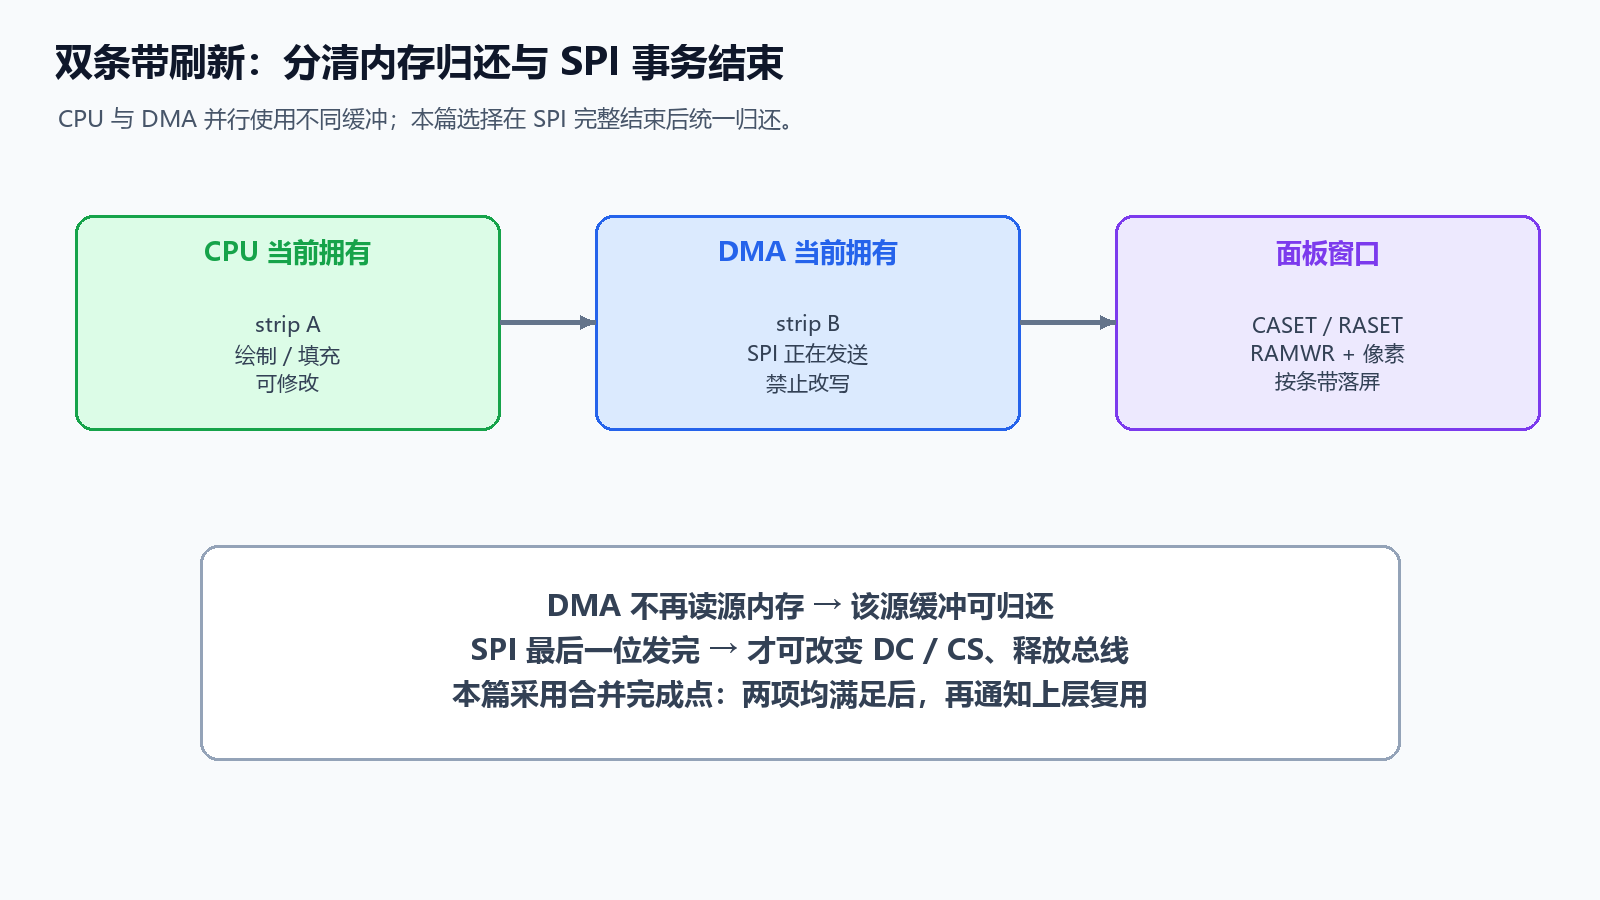

```text
FREE → CPU_FILLING → READY → DMA_IN_FLIGHT → FREE
                                    ↓错误
                         停止外设、确认不再借用 → ERROR/FREE
```

提交后缓冲属于驱动，CPU不能继续改。完成点包括DMA不再读源内存，以及SPI移位器最后一位已发完；然后才改DC/CS和释放总线。底层若明确已复制到自己的缓存，可以更早归还输入缓冲，但必须把合同写清楚。

双缓冲A/B可以CPU填B、DMA发A；如果两块都在用，等待或丢弃新的刷新请求，不能覆盖A。小命令可同步发送，大像素块可DMA；先做到单事务正确，再优化流水线。

参考ST7789实现有等待DMA状态的循环，但没有代表本篇已做有界GD32异步驱动。借鉴结构时补返回码、超时、错误中断和取消流程，不把等待状态永远不变化的问题留给上层。

若芯片启用了数据Cache，按内存区和DMA方向维护cache，并满足对齐；本示例平台是否存在/启用相关cache须按实际芯片确认，不能机械加入其它MCU的cache API。同步问题、内存可达性和cache问题应分别诊断。

传输错误后不能先释放一个局部buffer再停止DMA。先确认外设停止借用，再收回所有权，重新设窗口恢复；图形库的flush完成通知也必须遵守其线程/ISR约定。


## 22. 局部刷新、脏矩形与撕裂

变化区域称脏矩形。文本/图标/波形更新后记录目标区域，只重绘这些部分；重叠相邻区域适当合并，减少窗口次数。脏矩形列表满时可退化整屏，不要静默丢刷新。

纯色背景可以窄矩形覆盖，波形一列更新可先擦除旧列再画新值。但系统状态应先在RAM更新，再由显示任务绘制快照，避免一半采用旧数值一半采用新数值。

LCD控制器一边扫描、一边收到新像素时可能出现撕裂。双缓冲保证CPU源数据一致，**不自动保证面板扫描无撕裂**；TE同步需要控制器/模块引出TE脚、时间预算和驱动支持。课程连接器图没有核对TE路径，本篇不声称已经配置同步。

显示任务不要毫无变化也以最高优先级反复清屏。先估算刷新区域、最大事务时间、触摸/采样截止时间，再确定任务优先级和刷新周期。共享SPI读资源时，可按条带分次持锁，给其它设备合理机会；同一窗口需要保持的状态也要明确。


## 23. CST816T地址、复位与事件通知

课程用7位设备地址 `0x15`，线上写/读地址字节分别0x2A/0x2B。底层API若接受7位地址，传0x15；若接受带读写位的地址字节，则按其约定，不把I²C地址常量和寄存器地址混淆。

可见两处复位片段分别采用10ms低/50ms等待和1ms低/1ms等待，不能把它们都视作通用规格。采用完整型号手册或已验证模块初始化方案，按板例PD7控制复位，复位期间屏蔽/管理EXTI并在ready后处理积压事件。

课程在PB4设置EXTI4通知MCU读取；边沿/电平、自动睡眠与唤醒、事件是否锁存由触摸固件决定。INT并不等于“手指必定按下”，可能是移动、抬起或手势变化。

`0xA7`读芯片ID、`0xA9`读版本是课程说明；本篇未验证特定后缀的ID固定值，不填写“读到某值就一定正确”的常量。通信错误、sleep未唤醒和错误地址都要记录，未知ID不应继续写未经核对的模式寄存器。


## 24. 读取寄存器与解码12位坐标

| 寄存器 | 课程字段 |
|---:|---|
| 0x01 | GestureID |
| 0x02 | FingerNum |
| 0x03、0x04 | X高4位、低8位 |
| 0x05、0x06 | Y高4位、低8位 |

课程可见最终函数按上述顺序分别读取6次。下面用**已完整读到的6字节数组**解释解码；若改为从0x01开始连续读6字节，必须先确认实物支持寄存器自增/快照规则。

```c
typedef struct {
    uint8_t gesture, fingers;
    uint16_t x, y;
} app_touch_raw_t;

bool app_touch_decode(const uint8_t data[6], app_touch_raw_t *out)
{
    if (data == NULL || out == NULL) return false;
    out->gesture = data[0];
    out->fingers = data[1]; /* 若实际字段含其它标志，按手册再掩码 */
    out->x = (uint16_t)(((uint16_t)(data[2] & 0x0Fu) << 8) | data[3]);
    out->y = (uint16_t)(((uint16_t)(data[4] & 0x0Fu) << 8) | data[5]);
    return true;
}
```

高字节低4位参与坐标，忽略的高4位可能有事件信息，若手册定义应单独解析。12位字段理论0～4095，**不意味着屏幕实际有4096像素，也不意味着必须除以4095缩放**。课程240×280像素化输出时，接受x<240、y<280。

通信失败不要解析未初始化或部分旧数组。只有6字节请求完整成功才发布新样本；分多次读可能遇到不同扫描帧，必要时按器件快照规则检查/重读，连续读也不自动证明寄存器原子锁存。

测试数据 `{0x00,0x01,0x00,0xEF,0x01,0x17}` 解码为x239、y279、finger1。把X高字节改为0xF0时低4位仍为0，坐标仍239；这可以验证未错误把高事件位拼进坐标。

本篇没有把课程“六次单字节读”的接口原样包装成无返回值函数。建议：

```c
/* board实现：7位address7、起始reg、完整读取length；
   成功读满，错误时out内容不发布。 */
app_io_result_t board_i2c_read_regs7(uint8_t address7, uint8_t reg,
                                    uint8_t *out, size_t length);

/* 若器件确认支持连续读，才能使用本流程 */
bool app_touch_read_raw(app_touch_raw_t *sample)
{
    uint8_t bytes[6];
    if (sample == NULL) return false;
    if (board_i2c_read_regs7(0x15u, 0x01u, bytes, sizeof bytes) != APP_IO_OK)
        return false;
    return app_touch_decode(bytes, sample);
}
```

典型寄存器读是Start→addr+W→reg→Repeated Start→addr+R→数据→末字节NACK→Stop，具体器件若允许Stop分段按手册；I²C最后一字节NACK是主机结束读，不等于设备通信故障。课程的soft_iic_read内部细节未完整核实，本篇不冒充已验收的总线实现。


## 25. EXTI到任务：短中断、有界总线

课程ISR直接调用触摸读函数，函数内还可能printf。本篇建议 ISR清MCU中断标志并用**可在ISR调用的事件通知**唤醒触摸任务，任务锁I²C后读取、验证和发布：

```c
void EXTI4_IRQHandler(void)
{
    if (board_touch_irq_pending()) {
        board_touch_irq_clear();
        board_touch_notify_from_isr(); /* 需实现原子/RTOS ISR合法接口 */
    }
}
/* 任务：wait通知 → 读取完整样本 → 校验 → 坐标映射 → 输入队列 */
```

这些board函数是合同，不是厂商现成API。GD32要核对SYSCFG/EXTI路由、PB4对应线4、触发边沿、NVIC和中断函数名；FreeRTOS还要核对允许调用ISR API的中断优先级。清EXTI标志只清MCU侧，不必然完成触摸控制器事件处理。

简单 `volatile bool pending` 只适合“允许合并事件”的设计，且任务取出并清零必须防止ISR恰好置位导致丢通知。可用短临界区交换标志、原子计数或RTOS通知；volatile不提供原子复合操作，也不能保存所有触摸历史。

事件较快时，任务不无限重读让CPU忙循环；读取次数/耗时有上限，记录合并和异常。软I²C延时不能直接替成RTOS毫秒sleep，否则微秒波形失真；调度与时序函数在第08篇的总线层管理。


## 26. 按下、移动、抬起与通信故障

原始finger数和读结果转成**样本状态**，再生成应用事件：

| 当前状态 | 本次完整有效样本 | 事件 |
|---|---|---|
| RELEASED | finger1、有效点 | DOWN |
| PRESSED | finger1、位置改变 | MOVE |
| PRESSED | finger1、位置未变 | 可保持/节流，不重复DOWN |
| PRESSED | finger0 | UP，保留最后有效点 |
| 任意 | I²C失败/字段无效 | 标无效，按故障策略处理 |
| 长期PRESSED | 超过新样本期限 | CANCEL，防止卡死 |

通信失败**不等于正常抬起**。保留短时状态但标stale，或发CANCEL取消手势，不触发点击；避免“坐标无效→UP→按钮确认”造成假操作。连续多个错误超过预算，复位/重新探测并记录故障，恢复后重新建立DOWN。

课程演示单指，不凭FingerNum字段就宣称模块支持任意多指。未知finger数或手势编号按手册决定拒绝/支持，本篇教学只接受0/1。gesture和DOWN/MOVE/UP也不是一一对应，手势寄存器不能替代基础状态。

控制器可能只在某些事件中断，不保证每个周期都发“仍按下”通知；定期轮询和超时时间按INT/休眠配置确定。不能凭某个30ms假设让静止长按不断取消。

事件结构包括type、逻辑坐标、sample时间、有效性和会话/序列。保留最后有效坐标供UP处理，取消与正常UP分开。记录触摸错误次数和最大样本年龄，让“偶尔不灵”有可诊断的数据。

下面是**有界、只维护一个当前触点**的应用状态逻辑说明，按已完整验证的样本驱动：

```text
处理有效finger1：
    未按下 → 保存x/y、时间 → 产生DOWN
    已按下 → 更新x/y、时间 → 位移需要时产生MOVE
处理有效finger0：
    已按下 → 产生UP(最后有效x/y) → 清pressed
    未按下 → 保持released
处理读取失败/字段无效：
    增加错误计数，标stale
    超过策略阈值且pressed → CANCEL(最后有效点) → 清pressed
```

一次错误不产生确认click；CANCEL只清捕获和视觉按下态。关键事件发送失败时，应用必须重同步而非继续认为队列完整。操作安全性由UI业务决定，本篇只准备普通画点/按钮事件，不引入任何控制电机动作。


## 27. 统一显示与触摸的坐标旋转

本篇定义基准面板W=240、H=280，原始点已校准到 `[0,W)×[0,H)`。数学旋转按屏幕向下的Y轴定义为视觉顺时针，每个分支输出尺寸不同：

| 旋转 | 输出尺寸 | 映射 |
|---|---|---|
| 0° | W×H | (x,y)=(rx,ry) |
| 90° | H×W | (x,y)=(H-1-ry,rx) |
| 180° | W×H | (x,y)=(W-1-rx,H-1-ry) |
| 270° | H×W | (x,y)=(ry,W-1-rx) |

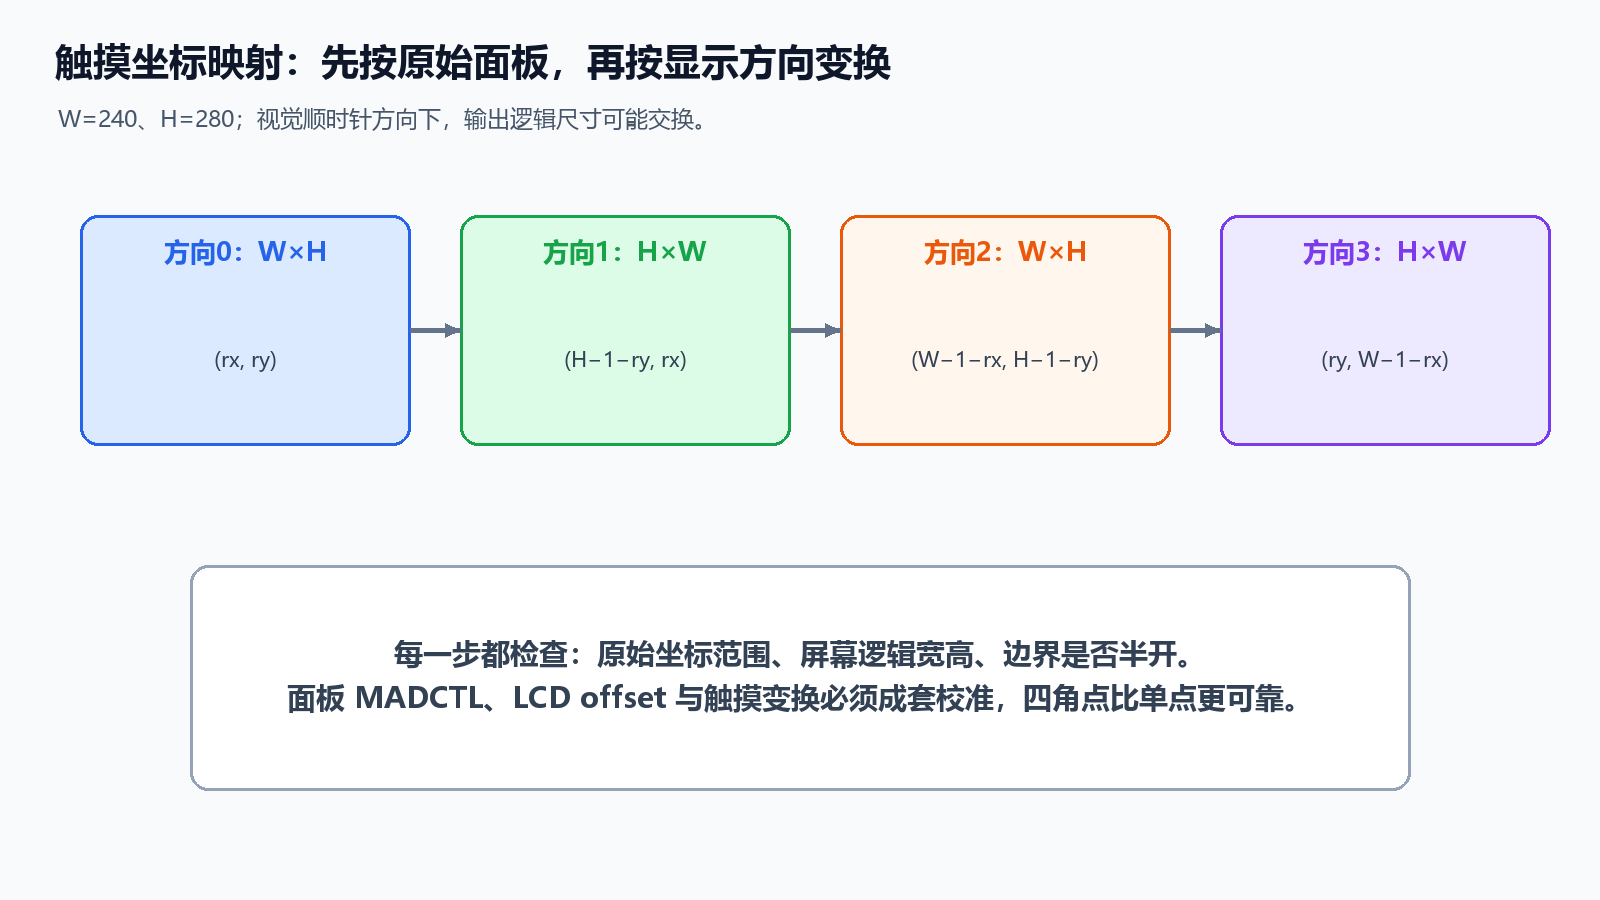

```c
bool app_touch_rotate(uint16_t rx, uint16_t ry, unsigned rotation,
                      uint16_t *x, uint16_t *y)
{
    if (x == NULL || y == NULL || rx >= 240u || ry >= 280u ||
        rotation > 3u) return false;
    switch (rotation) {
    case 0: *x = rx;              *y = ry;              break;
    case 1: *x = (uint16_t)(279u - ry); *y = rx;         break;
    case 2: *x = (uint16_t)(239u - rx); *y = (uint16_t)(279u - ry); break;
    case 3: *x = ry;              *y = (uint16_t)(239u - rx); break;
    }
    return true;
}
```

数学rotation与参考库MADCTL编号可能不同，用显示四角图建立对应，再统一app层。显示逻辑旋转若已由MADCTL完成，触摸只按同一逻辑坐标变换一次；CPU不能又把渲染坐标旋转两遍。

原始触摸若确实是未校准量，应先校准/镜像到基准面板坐标，再旋转。电容触摸常返回像素坐标，不应不问分辨率就按4095缩放。镜像用 `W-1-x`，而不是W-x；校准误差、offset和轴交换分别验证。

四角映射可直接用来验收：

| 基准点 | 0° | 90° | 180° | 270° |
|---|---|---|---|---|
| 左上(0,0) | (0,0) | (279,0) | (239,279) | (0,239) |
| 右上(239,0) | (239,0) | (279,239) | (0,279) | (0,0) |
| 右下(239,279) | (239,279) | (0,239) | (0,0) | (279,0) |
| 左下(0,279) | (0,279) | (0,0) | (239,0) | (279,239) |

校准可用原始范围rx_min～rx_max映射到0～W-1，分母不能为0，使用有符号/更宽中间值，越范围标无效再按明示容差处理。若感测平面倾斜，可需要二维仿射而非独立X/Y比例。参数需记录方向、尺寸和版本，换屏后不继续沿用旧校准。


## 28. 命中测试、点击与边缘处理

本篇按钮矩形 `[20,100)×[40,80)` 包含x20～99、y40～79。命中用有符号中间值处理app区域：

```c
bool app_hit_test(int32_t x, int32_t y, app_rect_t r)
{
    return r.x0 < r.x1 && r.y0 < r.y1 &&
           r.x0 <= x && x < r.x1 && r.y0 <= y && y < r.y1;
}
```

按下记录捕获目标；移动超过阈值可变成拖动/滑动；在同一目标内正常抬起才触发click。超时、I²C故障和队列丢关键事件用CANCEL，不确认点击。按一下可能有多个采样，不能每次finger1都重复执行动作。

触摸边缘若有噪声，先检查电气、校准和方向。允许的容差或滞回写成策略，并保留原始坐标诊断；不把所有无效坐标强行钳到(239,279)制造边缘误触。

MOVE可以合并到最新位置，DOWN/UP/CANCEL应保留。队列满时计数并取消当前手势/重同步，不能静默丢UP导致永久按下。事件时间用同一时基，校验顺序和样本年龄，不从printf到达时间推算触摸时刻。


## 29. 触摸画点与传感器显示案例

先实现无图形库的最小案例：清黑屏→画四角和中心标记→触摸任务发布逻辑点→显示任务在点附近画一个10×10方块→正常UP恢复状态。旧方块区域先重绘背景，新方块裁剪，靠近边缘不越界。

```text
触摸INT → 任务I²C读 → 有效性/范围 → 旋转 → 输入事件
                                              ↓
                                      应用状态（点/按钮）
                                              ↓
                          合并旧/新脏矩形 → 显示任务 → SPI
ADC采样 → 最新数值快照 ────────────────────────↑
```

第09篇ADC可提供温度/电位器值，界面每100ms更新字段，这是教学刷新节拍而非传感器硬件规格。采样任务维护数据与状态，显示任务绘制快照；避免直接在DMA ISR画数字。

传感器值失效要显示状态，不把旧温度当新温度；触摸失效也不更新标记成有效。每秒统计输入成功/错误、显示耗时、队列水位，区分UI卡顿与采样故障。

若图标从第10篇FatFS读取，先验证头和长度，再条带转换、持锁读取Flash、释放、切到LCD发送。LCD/Flash共享SPI时各自CS独立，I²C触摸也可能与OLED争用，性能预算包括全部设备。


## 30. 留给LVGL的驱动合同

课程“LVGL兼容手表屏”基于LVGL8.3，引用8.4移植文档；本篇只准备显示/输入合同，下一篇展开控件、事件、样式、tick、任务和资源。不要把8.x的注册结构与新版API混在同一工程。

显示层合同：逻辑分辨率/方向一致；刷新矩形约定明确；缓冲format/stride明确；SPI/DMA失败有恢复；异步完成才归还缓冲。LVGL8区域端点通常包含末点，转换到本篇半开区间须 `x1=area.x2+1`，同理y，先验证范围。

输入层合同：拿到最新有效逻辑坐标和pressed/released状态；读取回调不长时间阻塞I²C；错误CANCEL/stale策略转成库可理解的状态；最后UP点保留，坐标不重复旋转。

课程还给出FreeRTOS接管tick和延时的方案。注意RTOS tick不是天然1ms，换算毫秒必须按配置；`vTaskDelay(n)` 的单位是tick，常用 `pdMS_TO_TICKS(ms)`。微秒I²C时序不能套毫秒睡眠。GUI任务的优先级按采样/通信截止时间安排，不盲设最高。

移植验收顺序是裸显示→裸触摸→交互方块→图形库小控件→字体/图片→动画与性能。编译空间不足先读map区分RAM/Flash/某段，不简单通过缩小堆或添加NDEBUG掩盖问题。

统一ready意味着“绘图库可重用像素buffer”，不意味着“人眼已看到新帧”。输入到显示的延迟包含INT/轮询、I²C读、排队、UI处理、绘图、SPI传输和面板下一次扫描。定位响应迟缓时分别记录这几段，不只看主循环fps。

显示和输入都可以先实现同步接口获得可调试基线，随后把像素大块改成DMA；算法/坐标合同保持稳定，可以减少调试变量。下一篇接LVGL时使用同一套四角、纯色和触摸事件验收，防止库适配层重新引入swap或旋转。


## 31. 分层排错与上板实验

| 症状 | 优先排查 |
|---|---|
| LCD背光亮但没图 | RST、DC/CS、命令、sleep/display、像素模式 |
| 红蓝互换、绿正常 | RGB/BGR配置与资源通道 |
| 多色整体错误 | 字节序、COLMOD、数据位宽/长度 |
| 图像固定偏移/镜像 | 逻辑尺寸、MADCTL、panel offset |
| 随机横条/花屏 | SPI速率、线缆、供电、DMA复用、窗口争用 |
| OLED某页/列错 | 页/列模型、数组布局、控制器偏移 |
| 触摸无ACK | 电压、上拉、7/8位地址、复位与sleep |
| 坐标能打印但点偏 | 旋转、校准、边界、重复offset |
| 手指抬起还pressed | INT模式、事件丢失、故障/超时策略 |
| 接入LVGL后才错 | flush端点/format、完成点、输入映射、版本 |

**实验步骤**

1. 核对供电/针序；验证CS/DC/RST和I²C空闲状态；用低速起测。
2. ST7789黑白RGB三色，边框、四角编号、中心十字；记录四方向尺寸和offset。
3. 1px、跨边缘、空矩形、小图stride；检查目标外像素不变化。
4. 同步条带后DMA单/双缓冲；测试最后不满条带、长度限制和传输错误。
5. OLED y7/y8跨页、首末列、字形和局部更新；确认ACK与共享总线。
6. 触摸四角/中心raw数据，finger0/1、无效值、I²C失败、快速滑动和队列满。
7. 再做旋转画方块、按钮DOWN/MOVE/UP、长按与故障取消。
8. 测最大显示事务/触摸样本年龄/队列水位；接图形库后再重复关键验收。

本篇电脑只验证文档和独立算法，未运行这些上板实验。时钟、触摸INT规则、初始化最大等待、电气参数与信号质量仍要手册和测量。


## 32. 自测、答案、路线与可追溯来源

**自测题**

1. RGB565的R/G/B位数是什么？`#3469AA` 截断后是多少？
2. uint16_t红色0xF800在小端内存和本篇线上格式分别什么顺序？
3. 半开矩形(10,20)～(30,35)的末像素、总像素和字节数？
4. 240×280 RGB565整屏、240×20双条带各占多少RAM？
5. DMA结束后为何还要确认SPI最后一位完成？
6. 触摸12位字段是否必须按4095缩放？原始点(0,0)顺时针90°变成什么？
7. 7位触摸地址0x15对应写/读地址字节？I²C失败为何不等于UP？
8. OLED y=8落哪页哪bit？二维页布局为何影响flush？
9. 为什么双缓冲不自动消除面板撕裂？
10. 图形库flush何时可归还缓冲？如何把含末点转换成半开？

**答案要点**

1. R5/G6/B5，0x3355。
2. 内存00 F8，线上F8 00；bit发送方向不自动swap字节。
3. 末(29,34)，300像素、600B。
4. 134400B，双条带19200B；另算栈、资源和库工作区。
5. DMA可能已装入外设但移位仍进行中，此时改DC/CS会影响解释。
6. 不必，先查是否像素坐标；90°输出280×240，(279,0)。
7. 0x2A/0x2B；失败是未知状态，用stale/CANCEL策略避免假点击。
8. 页1、bit0；页/列维度不同导致连续方向与stride不同。
9. 面板扫描与写入仍可能交错；TE同步另需硬件和时序支持。
10. 驱动不再借用且完成规则满足后通知；终点加1并检查边界。

**十二篇路线**

| 编号 | 主题 | 本篇联系 |
|---|---|---|
| 01 | C语言核心语法与函数 | 位操作、函数与错误返回 |
| 02 | C语言指针与内存 | 像素buffer/stride/生存期 |
| 03 | 单片机入门与开发环境 | 工程移植、map与编译 |
| 04 | GPIO与基础外设控制 | CS/DC/RST/BLK |
| 05 | 中断与定时器 | EXTI与时基 |
| 06 | 串口、DMA与通信模块 | 数据搬运、诊断 |
| 07 | 实时时钟与系统管理 | 时间有效性、功耗 |
| 08 | I2C与SPI通信 | 显示/触摸总线 |
| 09 | ADC与传感器采集 | 界面数据生产者 |
| 10 | 存储器与文件系统 | 字库/图标资源 |
| **11** | **屏幕显示与触摸驱动** | **本篇** |
| 12 | LVGL图形界面开发 | 后续界面整合 |

**已读课程资料**

- [I2C OLED](https://www.yuque.com/xxcls/mcu/lt4wgoiodang2y3r)
- [SPI OLED](https://www.yuque.com/xxcls/mcu/hgpcdpgo10ixc3vv)
- [1.69寸手表屏-显示](https://www.yuque.com/xxcls/mcu/qf6ommba83gy8icq)
- [1.69寸手表屏-触摸](https://www.yuque.com/xxcls/mcu/vr8s9o01wbgamui1)
- [RGB565 RGB888](https://www.yuque.com/xxcls/mcu/ma5psop7a1anmgpe)
- [LVGL兼容手表屏](https://www.yuque.com/xxcls/mcu/xkqxppeyyxrk3lic)

用户原知识库为[embheima/mcu](https://www.yuque.com/embheima/mcu)，当前公开课程库为[xxcls/mcu](https://www.yuque.com/xxcls/mcu)。页面的可见代码和图不代表完整工程已编译验证。

**外部移植对照**

- [课程引用ST7789参考库](https://github.com/lbthomsen/stm32-st7789)：STM32 HAL移植参考，README提供尺寸、条带和线缆经验。
- [st7789.h固定提交](https://raw.githubusercontent.com/lbthomsen/stm32-st7789/8e36ca3d08b080e40659963547225f9f4d827212/src/st7789.h)：命令、颜色格式、MADCTL与偏移对照。
- [st7789.c固定提交](https://raw.githubusercontent.com/lbthomsen/stm32-st7789/8e36ca3d08b080e40659963547225f9f4d827212/src/st7789.c)：窗口、初始化、DMA与图像发送路径。
- [配置模板固定提交](https://raw.githubusercontent.com/lbthomsen/stm32-st7789/8e36ca3d08b080e40659963547225f9f4d827212/src/st7789_config.h.template)：平台宏与GPIO配置对照。
- [LVGL 8.4工程文档](https://docs.lvgl.io/8.4/porting/project.html)：初始化与工程配置衔接。

外部源码为版本化参考，不把其当前master直接视为课程附件；本篇代码算法/合同以自行编写为主。若后续直接复用源码，遵守该仓库许可证与出处；本篇没有创建含完整第三方驱动的工程。

**阅读与验证边界**

阅读日期2026-10-12。完整压缩包、长代码编辑器、ST7789V/CST816T精确后缀手册和OLED具体控制器资料未全部核实。初始化电气、最高时钟、触摸寄存器锁存/INT模式、真实panel offset和DMA可达性仍按实物资料验收。

自绘3张图、RGB565/裁剪/旋转/页缓冲算法、条带与带宽预算、错误策略是学习补充。电脑检查不等于C/SPL编译或上板验证；未烧录、未实际发送屏幕命令、未进行触摸或电气测量。
